In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Trần Công Nhân - 6451071054")

df = pd.read_csv('winequality-red.csv')
print("Kích thước dữ liệu:", df.shape)
display(df.head())

Trần Công Nhân - 6451071054
Kích thước dữ liệu: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [2]:
print("Trần Công Nhân - 6451071054")

print("Thông tin dữ liệu:")
df.info()

print("\nSố lượng giá trị bị thiếu (Missing values) ở từng cột:")
print(df.isnull().sum())

print("\nSố dòng bị trùng lặp:", df.duplicated().sum())
# Xóa các dòng trùng lặp (nếu đề yêu cầu làm sạch dữ liệu)
df = df.drop_duplicates()
print("Kích thước dữ liệu sau khi làm sạch:", df.shape)

Trần Công Nhân - 6451071054
Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Số lượng giá trị bị thiếu (Missing values) ở từng cột:
fixed acidity          

Trần Công Nhân - 6451071054


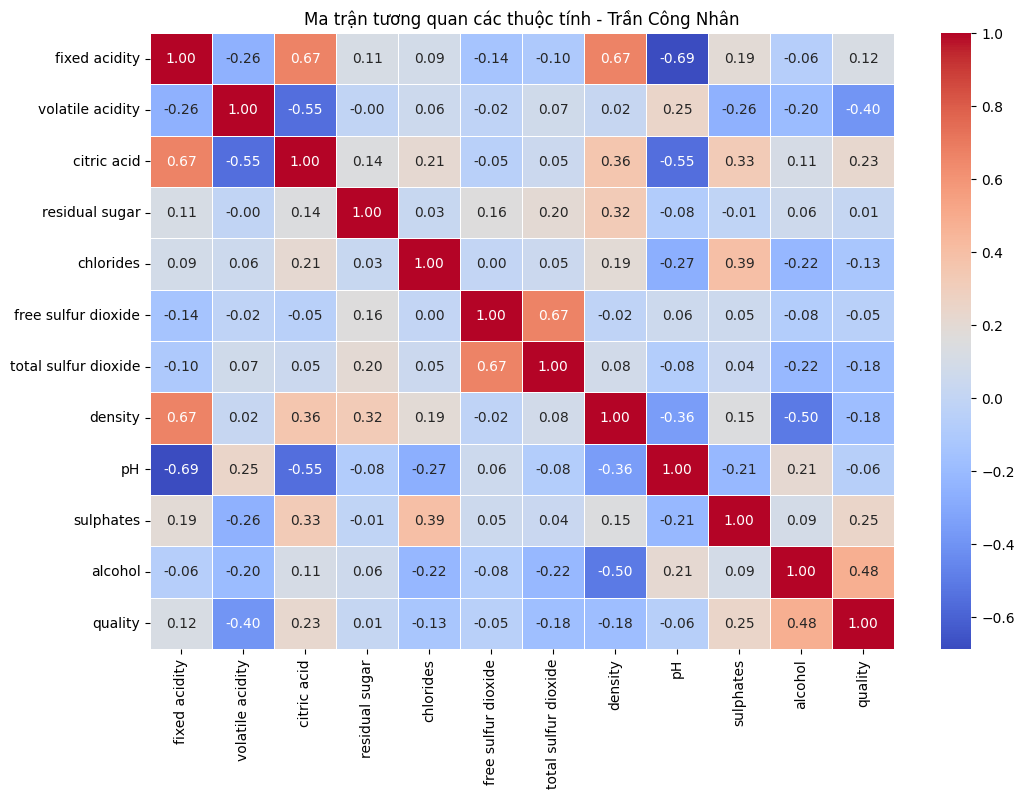

In [3]:
print("Trần Công Nhân - 6451071054")

plt.figure(figsize=(12, 8))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Ma trận tương quan các thuộc tính - Trần Công Nhân")
plt.show()

In [4]:
print("Trần Công Nhân - 6451071054")

X = df.drop('quality', axis=1)
y = df['quality']

print("Kích thước X (thuộc tính điều kiện):", X.shape)
print("Kích thước y (thuộc tính quyết định):", y.shape)
print("\nPhân bố các nhãn trong y:")
print(y.value_counts().sort_index())

Trần Công Nhân - 6451071054
Kích thước X (thuộc tính điều kiện): (1359, 11)
Kích thước y (thuộc tính quyết định): (1359,)

Phân bố các nhãn trong y:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [5]:
print("Trần Công Nhân - 6451071054")

categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print("Các cột dạng phi số trong X:", categorical_cols)

if len(categorical_cols) == 0:
    print("Tất cả thuộc tính điều kiện đều đã ở dạng số, sẵn sàng đưa vào mô hình.")
else:
    X = pd.get_dummies(X, columns=categorical_cols)

Trần Công Nhân - 6451071054
Các cột dạng phi số trong X: []
Tất cả thuộc tính điều kiện đều đã ở dạng số, sẵn sàng đưa vào mô hình.


In [6]:
print("Trần Công Nhân - 6451071054")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

Trần Công Nhân - 6451071054
Kích thước X_train: (951, 11)
Kích thước X_test: (408, 11)
Kích thước y_train: (951,)
Kích thước y_test: (408,)


Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) mô hình ID3: 0.5000

Báo cáo phân lớp (Classification Report) - ID3:
              precision    recall  f1-score   support

           3       0.25      0.20      0.22         5
           4       0.07      0.08      0.07        13
           5       0.61      0.59      0.60       172
           6       0.51      0.48      0.50       164
           7       0.35      0.44      0.39        50
           8       0.00      0.00      0.00         4

    accuracy                           0.50       408
   macro avg       0.30      0.30      0.30       408
weighted avg       0.51      0.50      0.51       408



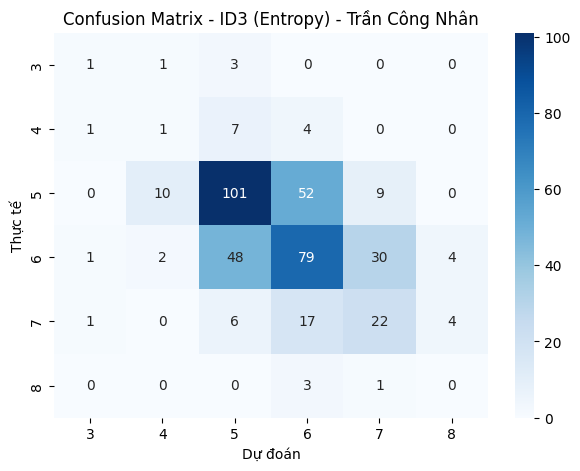

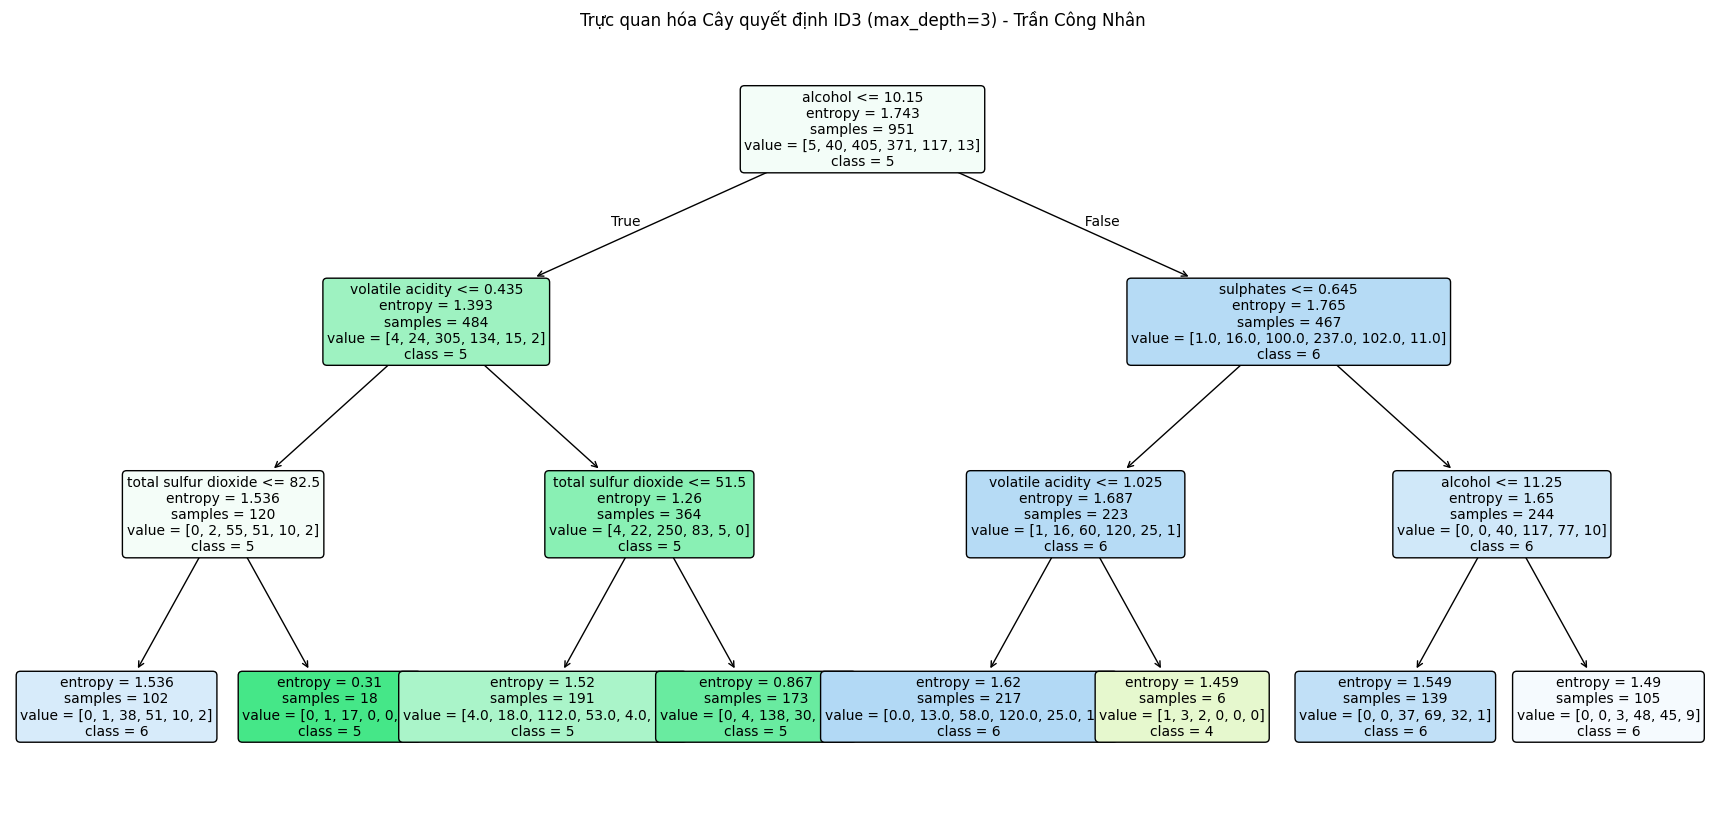

In [7]:
print("Trần Công Nhân - 6451071054")

# Huấn luyện mô hình ID3
id3_model = DecisionTreeClassifier(criterion='entropy', random_state=42)
id3_model.fit(X_train, y_train)

# Dự đoán và đánh giá
y_pred_id3 = id3_model.predict(X_test)
acc_id3 = accuracy_score(y_test, y_pred_id3)

print(f"Độ chính xác (Accuracy) mô hình ID3: {acc_id3:.4f}")
print("\nBáo cáo phân lớp (Classification Report) - ID3:")
print(classification_report(y_test, y_pred_id3, zero_division=0))

# Vẽ Confusion Matrix
plt.figure(figsize=(7, 5))
labels = sorted(y.unique())
cm_id3 = confusion_matrix(y_test, y_pred_id3, labels=labels)
sns.heatmap(cm_id3, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - ID3 (Entropy) - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

# Trực quan hóa cây quyết định ID3 (giới hạn max_depth=3 để dễ nhìn)
id3_vis = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
id3_vis.fit(X_train, y_train)

plt.figure(figsize=(22, 10))
plot_tree(
    id3_vis,
    feature_names=X_train.columns,
    class_names=[str(c) for c in labels],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Trực quan hóa Cây quyết định ID3 (max_depth=3) - Trần Công Nhân")
plt.show()

Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) mô hình Naive Bayes: 0.5319

Báo cáo phân lớp (Classification Report) - Naive Bayes:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         5
           4       0.17      0.46      0.25        13
           5       0.66      0.65      0.66       172
           6       0.55      0.43      0.48       164
           7       0.40      0.58      0.47        50
           8       0.00      0.00      0.00         4

    accuracy                           0.53       408
   macro avg       0.30      0.35      0.31       408
weighted avg       0.56      0.53      0.54       408



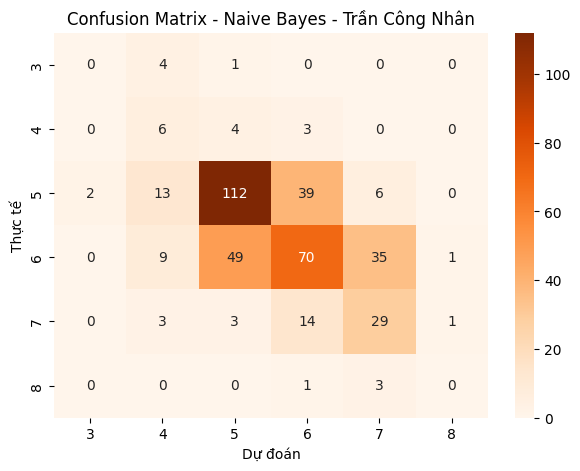

In [8]:
print("Trần Công Nhân - 6451071054")

# Huấn luyện mô hình Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Dự đoán và đánh giá
y_pred_nb = nb_model.predict(X_test)
acc_nb = accuracy_score(y_test, y_pred_nb)

print(f"Độ chính xác (Accuracy) mô hình Naive Bayes: {acc_nb:.4f}")
print("\nBáo cáo phân lớp (Classification Report) - Naive Bayes:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

# Vẽ Confusion Matrix
plt.figure(figsize=(7, 5))
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=labels)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - Naive Bayes - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

Trần Công Nhân - 6451071054


,Mô hình,Accuracy
0,ID3 (Entropy),0.500000
1,CART (Gini),0.507353
2,Naive Bayes,0.531863


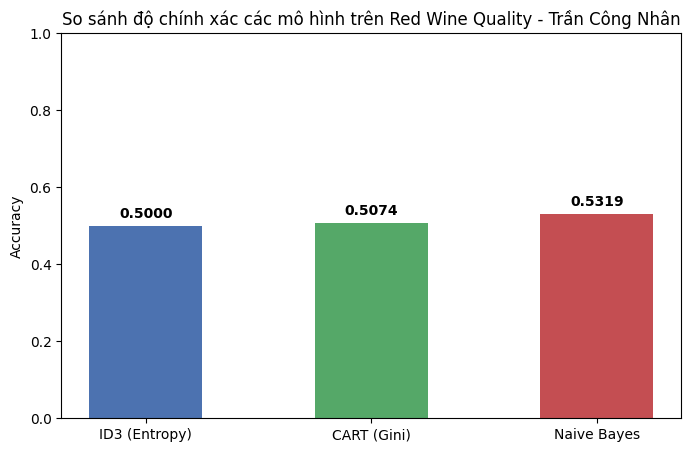

In [11]:
print("Trần Công Nhân - 6451071054")

# Tính lại độ chính xác để đảm bảo biến luôn tồn tại
acc_id3 = accuracy_score(y_test, DecisionTreeClassifier(criterion='entropy', random_state=42).fit(X_train, y_train).predict(X_test))
acc_cart = accuracy_score(y_test, DecisionTreeClassifier(criterion='gini', random_state=42).fit(X_train, y_train).predict(X_test))
acc_nb = accuracy_score(y_test, GaussianNB().fit(X_train, y_train).predict(X_test))

model_names = ['ID3 (Entropy)', 'CART (Gini)', 'Naive Bayes']
accuracies = [acc_id3, acc_cart, acc_nb]

# Bảng tổng hợp kết quả
df_results = pd.DataFrame({
    'Mô hình': model_names,
    'Accuracy': accuracies
})
display(df_results)

# Biểu đồ cột so sánh
plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, accuracies, color=['#4C72B0', '#55A868', '#C44E52'], width=0.5)
plt.ylim(0, 1.0)
plt.ylabel('Accuracy')
plt.title('So sánh độ chính xác các mô hình trên Red Wine Quality - Trần Công Nhân')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.02, f'{height:.4f}', ha='center', fontweight='bold')

plt.show()

# Mục mới

Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) mô hình CART: 0.5074

Báo cáo phân lớp (Classification Report) - CART:
              precision    recall  f1-score   support

           3       0.17      0.20      0.18         5
           4       0.12      0.15      0.13        13
           5       0.65      0.59      0.62       172
           6       0.49      0.50      0.50       164
           7       0.38      0.40      0.39        50
           8       0.00      0.00      0.00         4

    accuracy                           0.51       408
   macro avg       0.30      0.31      0.30       408
weighted avg       0.52      0.51      0.52       408



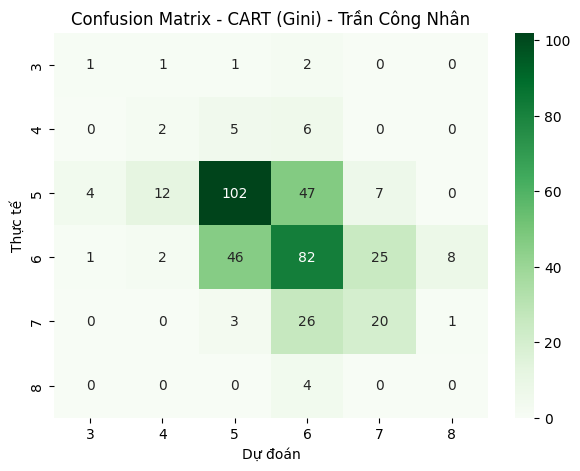

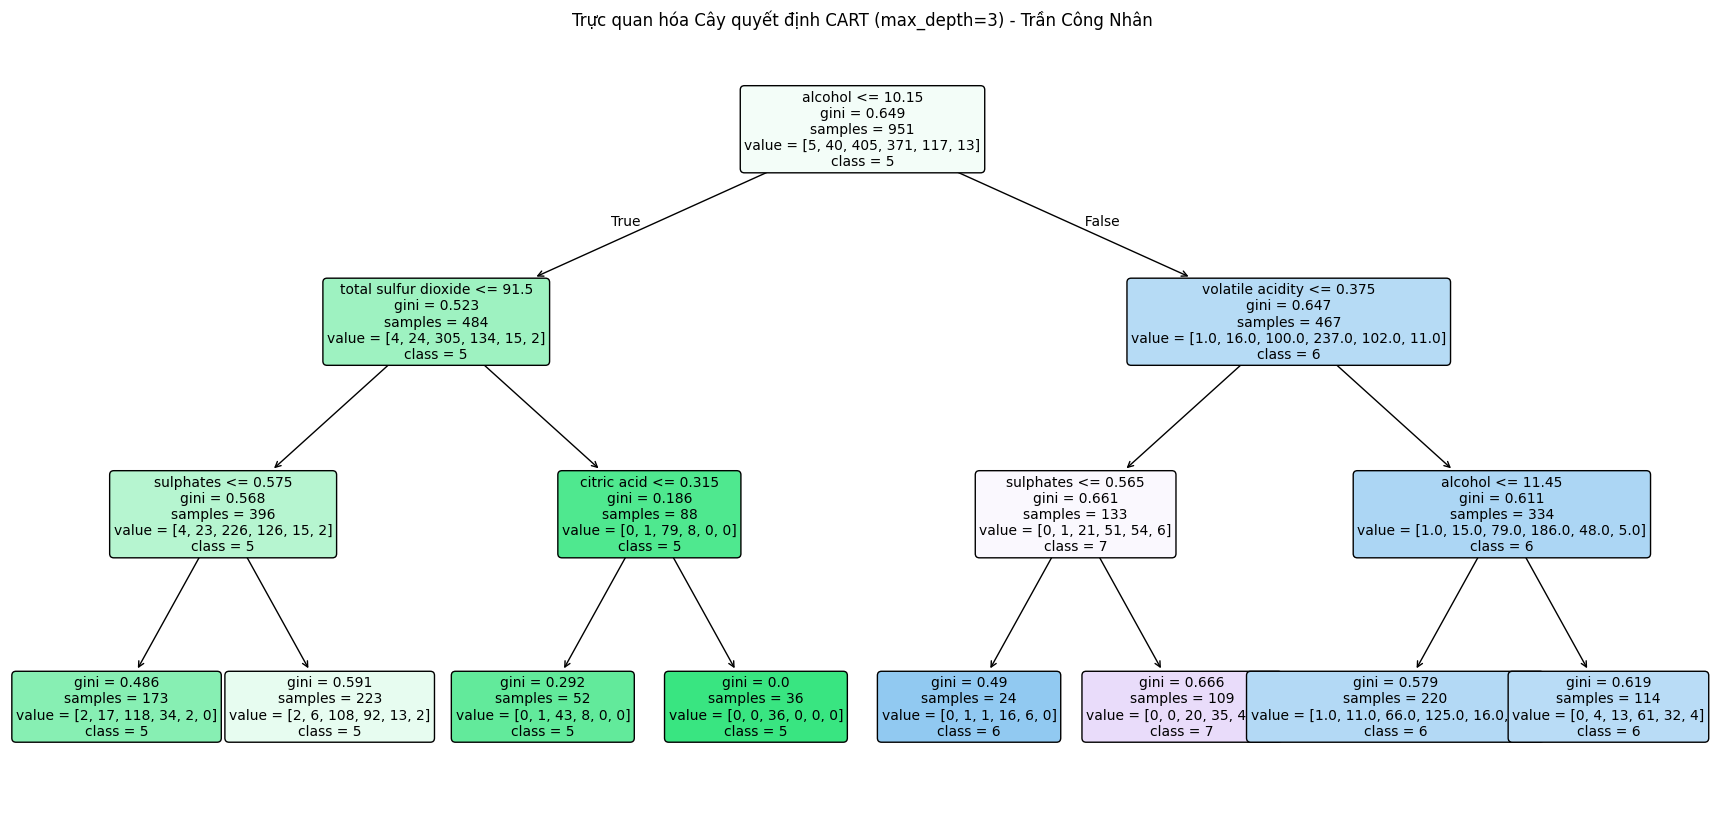

In [12]:
print("Trần Công Nhân - 6451071054")

# Huấn luyện mô hình CART
cart_model = DecisionTreeClassifier(criterion='gini', random_state=42)
cart_model.fit(X_train, y_train)

# Dự đoán và đánh giá
y_pred_cart = cart_model.predict(X_test)
acc_cart = accuracy_score(y_test, y_pred_cart)

print(f"Độ chính xác (Accuracy) mô hình CART: {acc_cart:.4f}")
print("\nBáo cáo phân lớp (Classification Report) - CART:")
print(classification_report(y_test, y_pred_cart, zero_division=0))

# Vẽ Confusion Matrix
plt.figure(figsize=(7, 5))
cm_cart = confusion_matrix(y_test, y_pred_cart, labels=labels)
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - CART (Gini) - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

# Trực quan hóa cây quyết định CART (giới hạn max_depth=3)
cart_vis = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
cart_vis.fit(X_train, y_train)

plt.figure(figsize=(22, 10))
plot_tree(
    cart_vis,
    feature_names=X_train.columns,
    class_names=[str(c) for c in labels],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Trực quan hóa Cây quyết định CART (max_depth=3) - Trần Công Nhân")
plt.show()